# 02 - NEWAVE: séries escolhidas pela ENA, GSF, preço e bandeira (com a Dcide)

**Pergunta:** usando um deck do NEWAVE do início do ano (jan ou fev/2026), quais das 2.000 séries escolhemos para prever cada
mês, como a ENA, o GSF e o preço delas se comparam com o real, e que bandeira resultaria — comparando também com o preço da
curva forward da **Dcide** publicada na época do deck.

**Métodos (D026; aqui a ENA de referência é a real, na prática será a do ECMWF):**
- **GSF:** em cada mês, média das **10 séries** com ENA do SIN do mês mais próxima da referência.
- **Preço:** as **25 séries** cuja trajetória de ENA do SIN (do início do deck até o mês) mais se aproxima da referência, com
  mais peso nos meses recentes; PLD gatilho de cada série pela fórmula do boletim (4 submercados).
- **Bandeira das séries:** cor com o GSF médio e o preço médio; a **probabilidade de cada cor** combina as 10 séries de GSF com
  as 25 de preço (250 combinações).
- **Bandeira da Dcide:** GSF das séries + preço da Dcide (PLD do SE; arquivo `dcide_<publicação>_<deck>.csv`).

In [1]:
import pandas as pd
from IPython.display import Image, display

from forecast_bandeiras import graficos, load, newave, regra

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
base = pd.read_parquet(load.DATA_PROCESSED / "base_mensal.parquet").loc["2026"]
base.index = base.index.month
base["cor_oficial"] = [c if isinstance(c, str) else r for c, r in zip(base.cor_boletim, base.cor_regra)]
ALVOS = [5, 6, 8, 10]
ABREV = {"Verde": "Vd", "Amarela": "Am", "Vermelha 1": "V1", "Vermelha 2": "V2"}

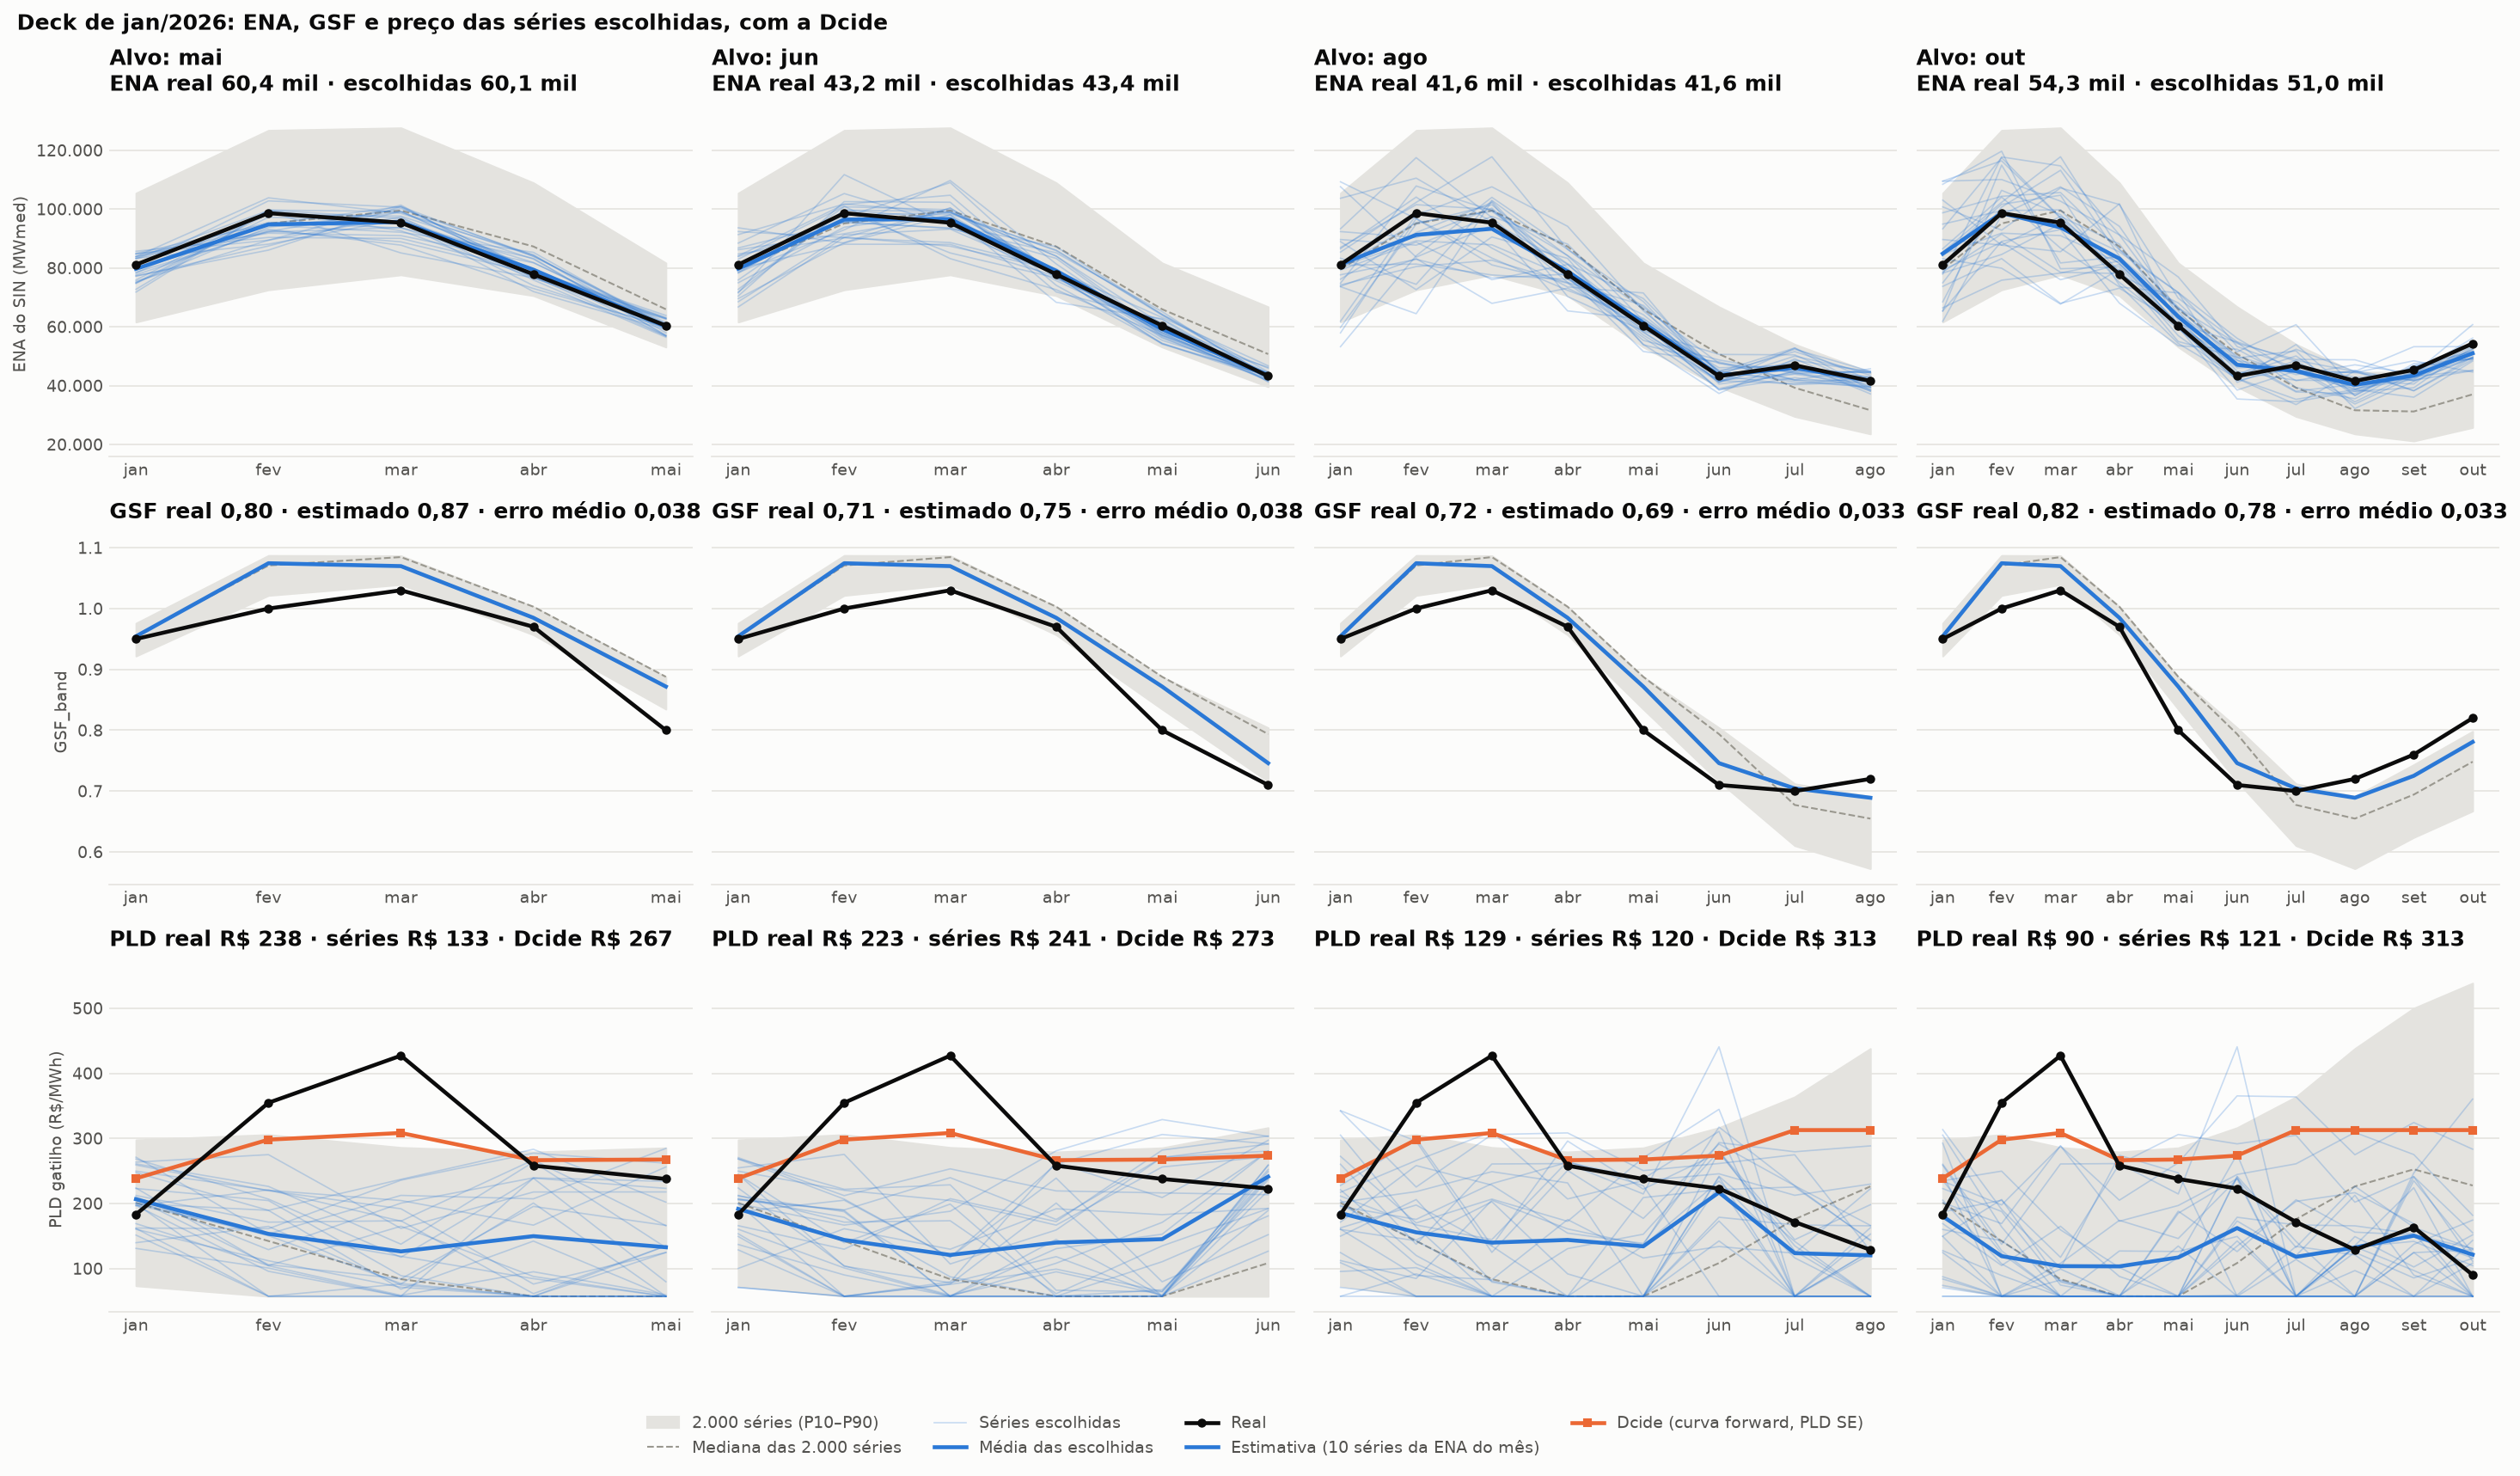

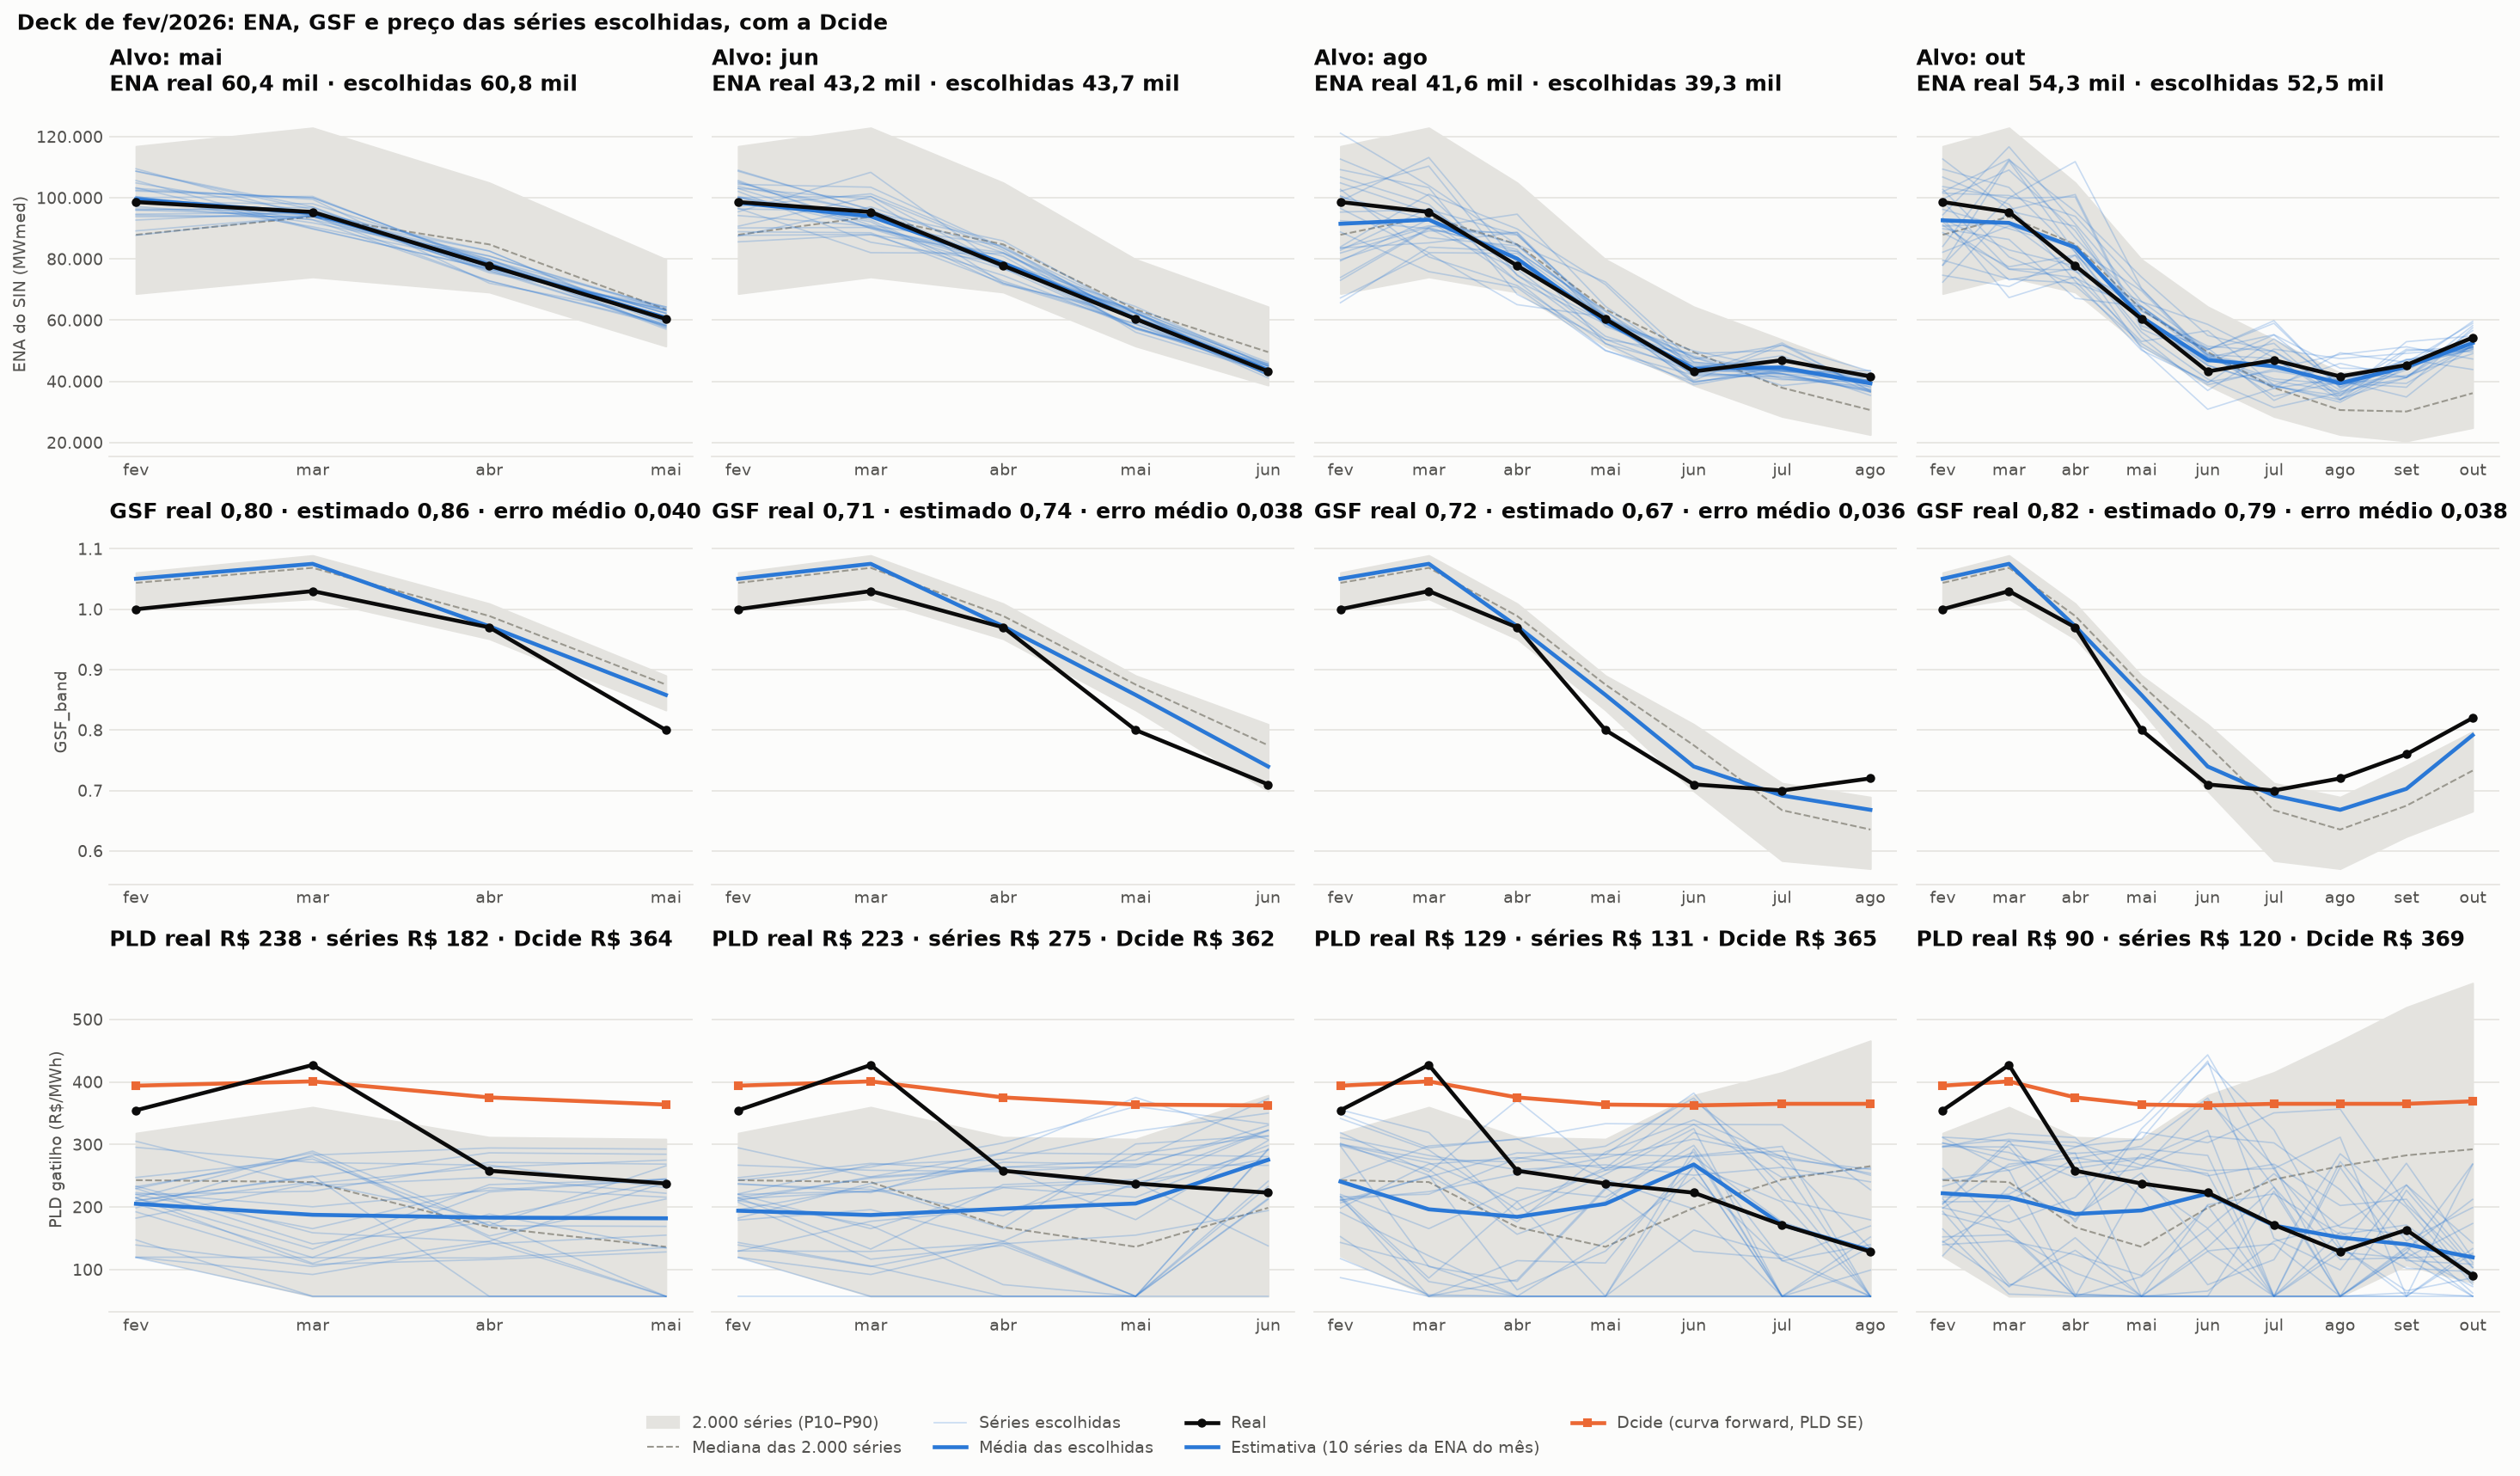

In [2]:
tabelas = {}
for mes_deck in (1, 2):
    deck = newave.carregar_deck(2026, mes_deck)
    meses = list(range(mes_deck, 11))
    ena = deck["ena_sin"][meses]
    gsf = newave.gsf_series(deck, base.loc[meses])
    pld = newave.pld_gatilho_series(deck, meses, base.pld_min_boletim.iloc[0], base.pld_max_boletim.max())
    dcide = load.ler_dcide(2026, mes_deck)
    dcide = dcide[dcide.index.year == 2026]
    dcide.index = dcide.index.month
    esc_gsf = {m: newave.escolher_series_mes(ena, m, base.loc[m, "ena_sin"], k=10) for m in meses}
    esc_preco = {m: newave.escolher_series(ena, base.loc[mes_deck:m, "ena_sin"], k=25) for m in meses}
    nome = f"{graficos.MESES[mes_deck - 1]}/2026"
    display(Image(graficos.trajetorias_deck(
        ena, gsf, pld, base, {a: esc_preco[a] for a in ALVOS}, esc_gsf, dcide,
        f"Deck de {nome}: ENA, GSF e preço das séries escolhidas, com a Dcide",
        f"08_trajetorias_deck_{mes_deck:02d}.png")))
    linhas = {}
    for m in meses:
        g, p = gsf.loc[esc_gsf[m], m], pld.loc[esc_preco[m], m]
        gsf_est = round(g.mean(), 2)
        prob = newave.probabilidade_cores(g, p)
        itens = [f"{ABREV[c]} {v:.0%}" for c, v in prob.items() if v >= 0.05]
        linhas[m] = {
            "cor_real": base.loc[m, "cor_oficial"],
            "cor_series": regra.cor_bandeira(gsf_est, p.mean()),
            "prob_series": " ".join(itens[:2]) + ("\n" + " ".join(itens[2:]) if len(itens) > 2 else ""),
            "prob_da_cor_real": prob[base.loc[m, "cor_oficial"]],
            "cor_dcide": regra.cor_bandeira(gsf_est, dcide.loc[m]),
            "gsf_real": base.loc[m, "gsf_band_boletim"], "gsf_est": gsf_est,
            "pld_real": base.loc[m, "pld_gatilho_boletim"], "pld_series": p.mean(), "pld_dcide": dcide.loc[m],
        }
    tabelas[f"Deck de {nome}"] = pd.DataFrame(linhas).T

## Bandeira: real × séries do NEWAVE × Dcide

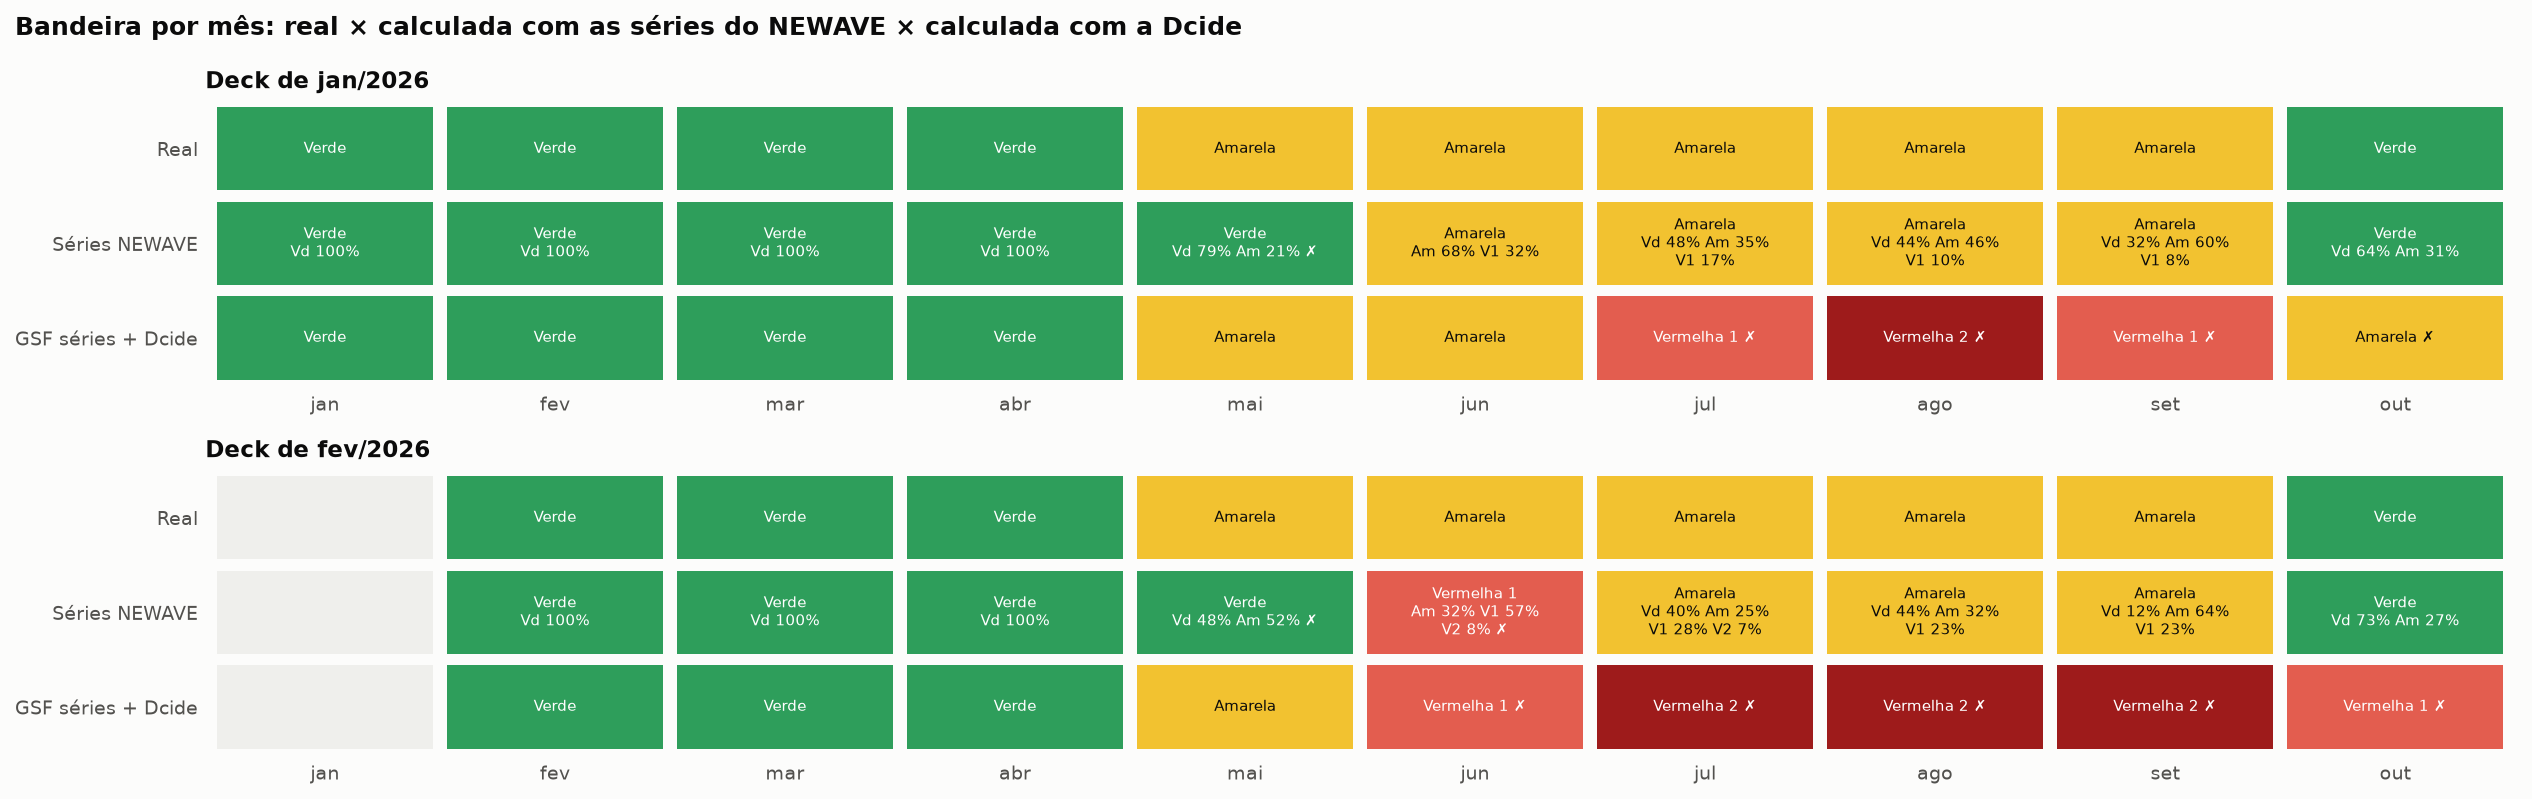

Deck de jan/2026 | cor certa — séries: 9 / 10 | Dcide: 6 / 10 | prob. média da cor real: 69%
Deck de fev/2026 | cor certa — séries: 7 / 9 | Dcide: 4 / 9 | prob. média da cor real: 64%


cor_real  cor_series prob_da_cor_real   cor_dcide  \
Deck de jan/2026 1     Verde       Verde             1.00       Verde   
                 2     Verde       Verde             1.00       Verde   
                 3     Verde       Verde             1.00       Verde   
                 4     Verde       Verde             1.00       Verde   
                 5   Amarela       Verde             0.21     Amarela   
                 6   Amarela     Amarela             0.68     Amarela   
                 7   Amarela     Amarela             0.35  Vermelha 1   
                 8   Amarela     Amarela             0.46  Vermelha 2   
                 9   Amarela     Amarela             0.60  Vermelha 1   
                 10    Verde       Verde             0.64     Amarela   
Deck de fev/2026 2     Verde       Verde             1.00       Verde   
                 3     Verde       Verde             1.00       Verde   
                 4     Verde       Verde             1.00       Verde   
                 5   Amarela       Verde             0.52     Amarela   
                 6   Amarela  Vermelha 1             0.32  Vermelha 1   
                 7   Amarela     Amarela             0.25  Vermelha 2   
                 8   Amarela     Amarela             0.32  Vermelha 2   
                 9   Amarela     Amarela             0.64  Vermelha 2   
                 10    Verde       Verde             0.73  Vermelha 1   

                    gsf_real gsf_est pld_real pld_series pld_dcide  
Deck de jan/2026 1      0.95    0.95   183.05     194.33    238.53  
                 2      1.00    1.07   354.65     120.44    298.01  
                 3      1.03    1.07   427.08     110.40    308.26  
                 4      0.97    0.98   258.01     153.64    266.48  
                 5      0.80    0.87   237.58     132.69    267.48  
                 6      0.71    0.75   222.92     241.13    273.41  
                 7      0.70    0.70   171.48     121.78    312.71  
                 8      0.72    0.69   128.67     120.25    312.71  
                 9      0.76    0.73   163.44     141.98    312.71  
                 10     0.82    0.78    90.19     121.41    312.71  
Deck de fev/2026 2      1.00    1.05   354.65     215.68    393.98  
                 3      1.03    1.08   427.08     174.10    400.86  
                 4      0.97    0.97   258.01     183.52    375.21  
                 5      0.80    0.86   237.58     181.98    363.77  
                 6      0.71    0.74   222.92     275.43    362.37  
                 7      0.70    0.69   171.48     157.95    364.99  
                 8      0.72    0.67   128.67     130.65    364.99  
                 9      0.76    0.70   163.44     164.60    364.99  
                 10     0.82    0.79    90.19     119.59    369.01

In [3]:
display(Image(graficos.faixa_bandeiras(
    tabelas, "Bandeira por mês: real × calculada com as séries do NEWAVE × calculada com a Dcide",
    "09_bandeiras_series_dcide.png")))
for nome, t in tabelas.items():
    print(nome, "| cor certa — séries:", (t.cor_series == t.cor_real).sum(), "/", len(t),
          "| Dcide:", (t.cor_dcide == t.cor_real).sum(), "/", len(t),
          "| prob. média da cor real:", f"{t.prob_da_cor_real.astype(float).mean():.0%}")
pd.concat(tabelas).drop(columns="prob_series")

## Leitura

- **GSF:** erro médio de 0,033–0,038 na trajetória; superestima em fev–mai e subestima levemente em ago–out (viés sazonal).
- **Preço das séries:** bom no período seco (jun–out); muito abaixo do real na transição úmido → seco (fev–mai).
- **Dcide:** o oposto. Acerta o nível na transição (mai: R\$ 267 contra R\$ 238 real; jun: R\$ 273 contra R\$ 223), mas no
  2º semestre ficou muito acima (R\$ 313–369 contra R\$ 90–171): o mercado precificou um 2º semestre mais seco do que o
  que ocorreu (o Sul ficou muito úmido). Com o GSF das séries, isso leva a vermelhas que não aconteceram.
- **Complementaridade:** a Dcide acerta maio (o mês que as séries erram) e as séries acertam jul–out (que a Dcide erra).
  Uma combinação por horizonte/estação (Dcide nos meses próximos e na transição, séries mais à frente) é candidata a testar
  com mais decks — com o cuidado de que isso aqui é um único ano visto em retrospecto.
- **Probabilidade:** em meses de fronteira a cor das médias e a cor mais provável podem diferir (ex.: deck de jan, jul:
  médias dão amarela, mas verde tem 48%). A probabilidade da cor real é a métrica a acompanhar no backtest.